# 30a. Label-only audit: how often common crash labels count a decline already in progress as positive

In the paper's decomposition, I compute π (the share of positives at which the decline is already in progress) from the label alone; for a model that ranks in-progress positives at least as high as pre-onset positives, at least a share π of its above-chance skill is detection. Here I therefore rebuild on public data the label conventions of literature Table S1 that I can reconstruct, without the original models, and measure how far an evaluation under each convention relies on detection. The reconstructions are approximate; I do not replicate any study's results or evaluate any study's conclusions.

| Name | Source | Label | Data |
|---|---|---|---|
| ranjan_spy_5d | Ranjan (2025) | sum of log returns over the next 5 trading days ≤ −1% | SPY daily |
| lleo_ziemba_2015 | Lleo & Ziemba (2015) | a fall of 10% or more below the current level within the next 252 trading days | S&P 500 daily |
| lleo_ziemba_2017 | Lleo & Ziemba (2017) | within the next 504 trading days, a day on which a 10% fall from the trailing 252-day high is first confirmed | S&P 500 daily |
| coudert_gex_2008 | Coudert & Gex (2008) crisis model | CMAX (index relative to its 24-month maximum) < mean − 2SD this month or within the next 12 months; the 11 months after a crisis excluded | S&P 500 monthly |
| shu_zhu_2020 | Shu & Zhu (2020) | a crash of 15% or more within the next 21 days (3 weeks) | Bitcoin daily |
| gsy_2019 | Greenwood, Shleifer & You (2019) | in industry-months with a 24-month return ≥ 100%, a 40% drawdown from the peak within the next 24 months | Fama–French 48 industries, monthly |
| le_hoang_2026_h1 / h10 | Le & Hoang (2026) | on days with VIX < 25, VIX ≥ 25 within the next 1 or 10 trading days | CBOE VIX daily (saved by notebook 29) |

- Already in progress (same rule for every label): at time t, the drawdown from the trailing W-period high is at least f times the label's decline size θ, where W is the label's natural peak period, f = 1/4 (main; the same ratio as the paper's 1%/4% onset) and f = 1/2 (secondary). For VIX I apply the same rule upward: a rise from the trailing 20-day low of at least f times the distance to 25.
- Quantities (no model): I compute π(f); the AUC of the current-drawdown score (no forecast content; it measures only how far the price has already fallen) overall, on not-yet-in-progress positives and on in-progress positives, with the in-progress share; and the AUC of a realized-volatility (regime) score overall and on not-yet-in-progress positives. The 95% intervals for π and the two AUCs come from 500 calendar-year block-bootstrap draws.
- Data: daily SPY, S&P 500 (^GSPC) and BTC-USD closes from Yahoo Finance and the value-weighted monthly returns of the 48 industry portfolios from the Kenneth French data library, through 2026-09-30 (copies in `AUDIT_data/`); the VIX file of notebook 29 (`FRED_daily/VIXCLS.csv`, 1990-01-02 to 2026-07-20).

I fix two descriptive flags in `30_SPEC.json`: a lower bound of π(1/4) of at least 0.5 ("most positives already in progress") and a lower bound of the current-drawdown AUC above 0.6 ("a no-forecast score looks skilled on this label"). This audit is descriptive and unrelated to the holdouts and the preregistration. I write the outputs to `label_only_audit_v1`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
OUT = SPOT_BASE / 'label_only_audit_v1'; OUT.mkdir(parents=True, exist_ok=True)
RAWA = DRIVE / 'AUDIT_data'; RAWA.mkdir(parents=True, exist_ok=True)
RAWV = DRIVE / 'FRED_daily'
M22 = SPOT_BASE / 'peak_window_v1'
DATA_END = '2026-09-30'; N_BOOT = 500; SEED = 20261031; F_MAIN, F_ALT = 0.25, 0.5
FF48_URL = 'https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/48_Industry_Portfolios_CSV.zip'
CONVENTIONS = {
    'ranjan_spy_5d': dict(anchor='current level (forward return)', source='Ranjan (2025)', data='SPY daily (Yahoo)', theta=0.01, W=5, freq='D'),
    'lleo_ziemba_2015': dict(anchor='current level (forward return)', source='Lleo & Ziemba (2015)', data='S&P 500 daily (Yahoo ^GSPC)', theta=0.10, W=252, freq='D'),
    'lleo_ziemba_2017': dict(anchor='past peak (breach date)', source='Lleo & Ziemba (2017)', data='S&P 500 daily (Yahoo ^GSPC)', theta=0.10, W=252, freq='D'),
    'coudert_gex_2008': dict(anchor='past peak (24-month max) incl. crisis months', source='Coudert & Gex (2008), crisis model', data='S&P 500 month-end (Yahoo ^GSPC)', theta=None, W=24, freq='M'),
    'shu_zhu_2020': dict(anchor='current level (forward return)', source='Shu & Zhu (2020)', data='BTC-USD daily (Yahoo)', theta=0.15, W=21, freq='D'),
    'gsy_2019': dict(anchor='current level and later peaks (forward drawdown)', source='Greenwood, Shleifer & You (2019), raw run-up', data='Fama-French 48 industries, monthly value-weighted', theta=0.40, W=24, freq='M'),
    'le_hoang_2026_h1': dict(anchor='fixed threshold (VIX 25)', source='Le & Hoang (2026), h = 1', data='CBOE VIX daily (saved by notebook 29)', theta=None, W=20, freq='D'),
    'le_hoang_2026_h10': dict(anchor='fixed threshold (VIX 25)', source='Le & Hoang (2026), h = 10', data='CBOE VIX daily (saved by notebook 29)', theta=None, W=20, freq='D')}
SPEC = {'title': 'Label-only audit of crash-label conventions on public data (descriptive)',
        'conventions': CONVENTIONS, 'in_progress_rule': 'drawdown from the trailing W-period high >= f * theta (VIX: rise from the trailing 20-day low >= f * distance to 25)',
        'f': [F_MAIN, F_ALT], 'scores': {'drawdown': 'current drawdown from the trailing W-period high (no forecast content)',
                                         'realized_vol': '20-day (daily) or 12-month (monthly) standard deviation of log returns',
                                         'vix': 'for VIX labels: rise from the trailing 20-day low (progression) and the VIX level (proximity)'},
        'quantities': 'pi(f) = share of positives already in progress (label-only lower bound on the detection share); AUC overall, on not-yet-in-progress positives and on in-progress positives',
        'bootstrap': f'{N_BOOT} draws, calendar-year blocks', 'data_end': DATA_END,
        'flags': 'pi(1/4) lower bound >= 0.5: most positives already in progress; drawdown AUC lower bound > 0.6: a no-forecast score looks skilled on this label',
        'anchoring': 'labels anchored at a past peak or fixed threshold give a decline already under way a mechanical head start; labels anchored at the current level '
                     '(forward returns) do not, so the no-forecast drawdown score is expected near 0.5 there while pi still counts positives issued after the decline began',
        'share_of_excess': 'reported only when |AUC - 0.5| >= 0.02',
        'caveat': 'label conventions are reconstructed approximately on public data; no study result is replicated or evaluated', 'seed': SEED}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
(OUT / '30_SPEC.json').write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/label_only_audit_v1 | spec sha256 b8b2f02117dbba74


## 1. Data

In [2]:
MANI = []


def yahoo_close(ticker, name):
    path = RAWA / f'{name}.csv'; src = None
    try:
        import yfinance as yf
        q = yf.download(ticker, start='1927-01-01', end='2026-10-31', auto_adjust=False, progress=False)
        q = q['Close'].squeeze() if 'Close' in q else q.squeeze()
        q = q.dropna()
        if len(q) < 500:
            raise RuntimeError('too few rows')
        pd.DataFrame({'date': q.index.strftime('%Y-%m-%d'), 'close': np.asarray(q, float)}).to_csv(path, index=False)
        src = f'Yahoo Finance {ticker} close, downloaded {pd.Timestamp.now(tz="UTC").floor("s")}'
    except Exception as e:
        if not path.is_file():
            print(f'{name}: unavailable ({type(e).__name__}: {str(e)[:80]}); conventions using it are skipped'); return None
        src = 'file saved earlier in AUDIT_data/'
    d = pd.read_csv(path); s = pd.Series(d.close.to_numpy(float), index=pd.to_datetime(d.date)).sort_index()
    s = s[~s.index.duplicated()].loc[:DATA_END]
    MANI.append(dict(series=name, source=src, sha256=sha256_file(path), rows=len(s), first=str(s.index.min().date()), last=str(s.index.max().date())))
    return s


def ff48_monthly():
    path = RAWA / 'ff48_vw_monthly.csv'; src = None
    try:
        req = urllib.request.Request(FF48_URL, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req, timeout=120) as r:
            zb = r.read()
        with zipfile.ZipFile(io.BytesIO(zb)) as z:
            txt = z.read(z.namelist()[0]).decode('latin-1')
        lines = txt.splitlines(); i0 = next(i for i, l in enumerate(lines) if 'Agric' in l)
        cols = [c.strip() for c in lines[i0].split(',')][1:]; rows = []
        for l in lines[i0 + 1:]:
            p = [x.strip() for x in l.split(',')]
            if not (len(p[0]) == 6 and p[0].isdigit()):
                break
            rows.append([p[0]] + p[1:])
        df = pd.DataFrame(rows, columns=['yyyymm'] + cols); df.to_csv(path, index=False)
        src = f'Kenneth French data library, 48 industries, value-weighted monthly, downloaded {pd.Timestamp.now(tz="UTC").floor("s")}'
    except Exception as e:
        if not path.is_file():
            print(f'FF48: unavailable ({type(e).__name__}: {str(e)[:80]}); gsy_2019 skipped'); return None
        src = 'file saved earlier in AUDIT_data/'
    df = pd.read_csv(path, dtype={'yyyymm': str}); idx = pd.to_datetime(df.yyyymm, format='%Y%m') + pd.offsets.MonthEnd(0)
    R = df.drop(columns='yyyymm').apply(pd.to_numeric, errors='coerce'); R.index = idx
    R = R.where(R > -99) / 100.0
    MANI.append(dict(series='ff48_vw_monthly', source=src, sha256=sha256_file(path), rows=len(R), first=str(R.index.min().date()), last=str(R.index.max().date())))
    return R.loc[:DATA_END]


def vix_saved():
    path = RAWV / 'VIXCLS.csv'
    if not path.is_file():
        print('VIX file from notebook 29 not found; le_hoang rows skipped'); return None
    d = pd.read_csv(path); d.columns = ['date', 'vix']; s = pd.Series(pd.to_numeric(d.vix, errors='coerce').to_numpy(), index=pd.to_datetime(d.date)).dropna().sort_index()
    s = s.loc['1990-01-01':'2026-07-20']
    MANI.append(dict(series='VIX (notebook 29 file)', source='FRED_daily/VIXCLS.csv', sha256=sha256_file(path), rows=len(s), first=str(s.index.min().date()), last=str(s.index.max().date())))
    return s


SPY = yahoo_close('SPY', 'spy_daily'); GSPC = yahoo_close('^GSPC', 'gspc_daily'); BTC = yahoo_close('BTC-USD', 'btc_usd_daily')
FF = ff48_monthly(); VIX = vix_saved()
MAN = pd.DataFrame(MANI); MAN.to_csv(OUT / '0_data_manifest.csv', index=False); display(MAN)

,series,source,sha256,rows,first,last
0,spy_daily,"Yahoo Finance SPY close, downloaded 2026-10-30...",8a529343a6f584b11829afdaeb11ca17b45d98274dd754...,8475,1993-01-29,2026-09-30
1,gspc_daily,"Yahoo Finance ^GSPC close, downloaded 2026-10-...",7f93d7f9eb83b5ec046010238fce5e5f37159e5eed002d...,24804,1927-12-30,2026-09-30
2,btc_usd_daily,"Yahoo Finance BTC-USD close, downloaded 2026-1...",03632a46479e6a9d2031c66f67c7420fe9d1967a48dcc2...,4397,2014-09-17,2026-09-30
3,ff48_vw_monthly,"Kenneth French data library, 48 industries, va...",e1b2eea7bbde4f9acb3422d7c569e952d3771a849bb8bb...,1203,1926-07-31,2026-09-30
4,VIX (notebook 29 file),FRED_daily/VIXCLS.csv,0faffcbf6267ea315e30914de687d6cdef023cc4b8bb87...,9232,1990-01-02,2026-07-20


## 2. Label reconstruction and computation

In [3]:
def fwd_min(p, h):
    """min of p[t+1 .. t+h]; NaN where the window runs past the end."""
    a = np.asarray(p, float); n = len(a); out = np.full(n, np.nan)
    if n > h:
        win = sliding_window_view(a[1:], h)          # win[i] = a[i+1 .. i+h]
        out[:len(win)] = win.min(axis=1)
    return out


def trailing_dd(p, W):
    s = pd.Series(np.asarray(p, float)); return (1 - s / s.rolling(W, min_periods=max(2, W // 2)).max()).to_numpy()


def realized_vol(p, W):
    s = pd.Series(np.log(np.asarray(p, float))).diff(); return s.rolling(W, min_periods=max(2, W // 2)).std().to_numpy()


def auc_or_nan(y, s):
    ok = np.isfinite(s)
    y, s = y[ok], s[ok]
    return roc_auc(y, s) if 0 < y.sum() < len(y) else np.nan


def roc_auc(y, s):
    r = pd.Series(s).rank().to_numpy(); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def split_auc(y, s, inp):
    """AUC overall, on not-yet-in-progress positives, on in-progress positives (all against all negatives), and the in-progress share of the excess."""
    neg = y == 0; pre = (y == 1) & ~inp; inn = (y == 1) & inp
    a = auc_or_nan(y, s)
    ap = auc_or_nan(np.r_[np.ones(pre.sum()), np.zeros(neg.sum())], np.r_[s[pre], s[neg]]) if pre.any() else np.nan
    ai = auc_or_nan(np.r_[np.ones(inn.sum()), np.zeros(neg.sum())], np.r_[s[inn], s[neg]]) if inn.any() else np.nan
    pi = inn.sum() / max(1, (y == 1).sum())
    return a, ap, ai, (pi * (ai - 0.5) / (a - 0.5) if np.isfinite(ai) and np.isfinite(a) and abs(a - 0.5) >= 0.02 else np.nan)   # undefined when there is no excess


CASES = {}     # name -> dict(y, dd, rv, theta, W, year, [prox])
if SPY is not None:
    p = SPY.to_numpy(); y = np.log(np.r_[p[5:], np.full(5, np.nan)] / p) <= np.log(1 - 0.01)
    ok = np.r_[np.ones(len(p) - 5, bool), np.zeros(5, bool)]
    CASES['ranjan_spy_5d'] = dict(y=y[ok].astype(int), dd=trailing_dd(p, 5)[ok], rv=realized_vol(p, 20)[ok], theta=0.01, year=SPY.index.year.to_numpy()[ok])
if GSPC is not None:
    g = GSPC.loc['1950-01-01':]; p = g.to_numpy(); n = len(p)
    m = fwd_min(p, 252); ok = np.isfinite(m)
    CASES['lleo_ziemba_2015'] = dict(y=(m[ok] <= 0.9 * p[ok]).astype(int), dd=trailing_dd(p, 252)[ok], rv=realized_vol(p, 20)[ok], theta=0.10, year=g.index.year.to_numpy()[ok])
    dd252 = trailing_dd(p, 252); crash = np.zeros(n, bool); armed = True; hi = -np.inf
    roll_hi = pd.Series(p).rolling(252, min_periods=126).max().to_numpy()
    for t in range(n):
        if armed and np.isfinite(dd252[t]) and dd252[t] >= 0.10:
            crash[t] = True; armed = False; hi = roll_hi[t]
        elif not armed and p[t] >= hi:
            armed = True
    cpos = np.flatnonzero(crash); y = np.zeros(n, int)
    for t in range(n):
        j = np.searchsorted(cpos, t, 'right'); y[t] = int(j < len(cpos) and cpos[j] <= t + 504)
    ok = np.arange(n) < n - 504
    CASES['lleo_ziemba_2017'] = dict(y=y[ok], dd=dd252[ok], rv=realized_vol(p, 20)[ok], theta=0.10, year=g.index.year.to_numpy()[ok])
    try:
        gm = g.resample('ME').last()
    except ValueError:
        gm = g.resample('M').last()
    pm = gm.to_numpy(); nm = len(pm)
    cmax = pm / pd.Series(pm).rolling(24, min_periods=24).max().to_numpy(); okc = np.isfinite(cmax)
    thr = np.nanmean(cmax) - 2 * np.nanstd(cmax); crisis = okc & (cmax < thr)
    yc = np.zeros(nm, int); drop = np.zeros(nm, bool); cpos = np.flatnonzero(crisis)
    for t in range(nm):
        yc[t] = int(any((cpos >= t) & (cpos <= t + 12)))
        drop[t] = (not crisis[t]) and any((cpos < t) & (cpos >= t - 11))
    ok = okc & ~drop & (np.arange(nm) < nm - 12)
    CASES['coudert_gex_2008'] = dict(y=yc[ok], dd=(1 - cmax)[ok], rv=realized_vol(pm, 12)[ok], theta=float(1 - thr), year=gm.index.year.to_numpy()[ok])
if BTC is not None:
    p = BTC.to_numpy(); m = fwd_min(p, 21); ok = np.isfinite(m)
    CASES['shu_zhu_2020'] = dict(y=(m[ok] <= 0.85 * p[ok]).astype(int), dd=trailing_dd(p, 21)[ok], rv=realized_vol(p, 20)[ok], theta=0.15, year=BTC.index.year.to_numpy()[ok])
if FF is not None:
    ys, dds, rvs, yrs = [], [], [], []
    for c in FF.columns:
        r = FF[c].dropna()
        if len(r) < 60:
            continue
        P = np.cumprod(1 + r.to_numpy()); n = len(P)
        run = np.full(n, np.nan); run[24:] = P[24:] / P[:-24] - 1
        fut = np.full(n, np.nan)
        for t in range(n - 24):
            path = P[t:t + 25]; fut[t] = np.max(1 - path / np.maximum.accumulate(path))
        sel = (run >= 1.0) & np.isfinite(fut)
        ys.append((fut[sel] >= 0.40).astype(int)); dds.append(trailing_dd(P, 24)[sel]); rvs.append(realized_vol(P, 12)[sel]); yrs.append(r.index.year.to_numpy()[sel])
    if ys:
        CASES['gsy_2019'] = dict(y=np.concatenate(ys), dd=np.concatenate(dds), rv=np.concatenate(rvs), theta=0.40, year=np.concatenate(yrs))
if VIX is not None:
    v = VIX.to_numpy(); low20 = pd.Series(v).rolling(20, min_periods=20).min().to_numpy(); n = len(v)
    for h in (1, 10):
        fut = np.full(n, np.nan); fut[:n - h] = sliding_window_view(v[1:], h).max(axis=1)[:n - h]
        ok = (v < 25) & np.isfinite(fut) & np.isfinite(low20)
        dist = 25 - low20
        CASES[f'le_hoang_2026_h{h}'] = dict(y=(fut[ok] >= 25).astype(int), dd=((v - low20) / dist)[ok], rv=v[ok], theta=1.0, year=VIX.index.year.to_numpy()[ok], vix=True)

rows = []; brow = []; rng = np.random.default_rng(SEED)
for name, c in CASES.items():
    y = c['y'].astype(int); dd = c['dd']; rv = c['rv']; th = c['theta']; yr = c['year']
    ok = np.isfinite(dd) & np.isfinite(rv); y, dd, rv, yr = y[ok], dd[ok], rv[ok], yr[ok]
    row = dict(convention=name, **{k: CONVENTIONS[name][k] for k in ('anchor', 'source', 'data', 'freq')}, n=len(y), positives=int(y.sum()), positive_rate=float(y.mean()))
    for f, tag in [(F_MAIN, 'q'), (F_ALT, 'h')]:
        inp = dd >= f * th
        row[f'pi_{tag}'] = float(inp[y == 1].mean()) if y.sum() else np.nan
        if tag == 'q':
            a, ap, ai, sh = split_auc(y, dd, inp)
            row.update(drawdown_auc=a, drawdown_auc_not_yet=ap, drawdown_auc_in_progress=ai, drawdown_in_progress_share_of_excess=sh)
            a2, ap2, _, _ = split_auc(y, rv, inp)
            row.update(vol_auc=a2, vol_auc_not_yet=ap2)
            INP = inp
    years = np.unique(yr); members = {k: np.flatnonzero(yr == k) for k in years}; bs = {'pi_q': [], 'drawdown_auc': [], 'vol_auc': []}
    for _ in range(N_BOOT):
        ii = np.concatenate([members[k] for k in rng.choice(years, len(years))]); yy = y[ii]
        if yy.sum() == 0 or yy.sum() == len(yy):
            continue
        bs['pi_q'].append(INP[ii][yy == 1].mean()); bs['drawdown_auc'].append(roc_auc(yy, dd[ii])); bs['vol_auc'].append(roc_auc(yy, rv[ii]))
    for k, vlist in bs.items():
        row[f'{k}_lo'], row[f'{k}_hi'] = (np.percentile(vlist, [2.5, 97.5]) if len(vlist) > 20 else (np.nan, np.nan))
    row['flag_most_positives_in_progress'] = bool(row['pi_q_lo'] >= 0.5)
    row['flag_no_forecast_score_looks_skilled'] = bool(row['drawdown_auc_lo'] > 0.6)
    rows.append(row)

# Reference row: this paper's own label (4% / 240 min, BTC 1-minute), from notebook 22 and Table 5 (notebook 23)
if (M22 / '2_per_minute_by_window.csv').is_file():
    r22 = pd.read_csv(M22 / '2_per_minute_by_window.csv'); r0 = r22[(r22.H == 240) & (r22.score == 'B0_RV24h_baseline')].iloc[0]
    rows.append(dict(convention='this_paper_btc_1m_4pct_240', anchor='past peak (breach of 4% below the 240-min high)', source='this paper (notebooks 22, 23)', data='Binance BTCUSDT spot, 1-minute, dev 2023-2026', freq='1min',
                     n=int(r0.n_pre + r0.n_in + r0.n_neg), positives=int(r0.n_pre + r0.n_in), positive_rate=float((r0.n_pre + r0.n_in) / (r0.n_pre + r0.n_in + r0.n_neg)),
                     pi_q=float(r0.share_in), pi_q_lo=float(r0.share_in_lo), pi_q_hi=float(r0.share_in_hi),
                     drawdown_auc=0.688, drawdown_auc_not_yet=0.517, drawdown_auc_in_progress=0.931, drawdown_in_progress_share_of_excess=0.95,
                     vol_auc=float(r0.auc_standard), vol_auc_not_yet=float(r0.auc_pre), note='onset = 1% below the event peak (event-anchored, not trailing-high rule); drawdown values from notebook 23'))
AUD = pd.DataFrame(rows); AUD.to_csv(OUT / '1_label_only_audit.csv', index=False)
show = ['convention', 'anchor', 'n', 'positive_rate', 'pi_q', 'pi_q_lo', 'pi_q_hi', 'pi_h', 'drawdown_auc', 'drawdown_auc_lo', 'drawdown_auc_not_yet', 'drawdown_in_progress_share_of_excess',
        'vol_auc', 'vol_auc_not_yet', 'flag_most_positives_in_progress', 'flag_no_forecast_score_looks_skilled']
display(AUD[[c for c in show if c in AUD]].round(3))

/tmp/ipykernel_2294/1788013370.py:97: RuntimeWarning: divide by zero encountered in divide
  CASES[f'le_hoang_2026_h{h}'] = dict(y=(fut[ok] >= 25).astype(int), dd=((v - low20) / dist)[ok], rv=v[ok], theta=1.0, year=VIX.index.year.to_numpy()[ok], vix=True)
/tmp/ipykernel_2294/1788013370.py:97: RuntimeWarning: invalid value encountered in divide
  CASES[f'le_hoang_2026_h{h}'] = dict(y=(fut[ok] >= 25).astype(int), dd=((v - low20) / dist)[ok], rv=v[ok], theta=1.0, year=VIX.index.year.to_numpy()[ok], vix=True)


,convention,anchor,n,positive_rate,pi_q,pi_q_lo,pi_q_hi,pi_h,drawdown_auc,drawdown_auc_lo,drawdown_auc_not_yet,drawdown_in_progress_share_of_excess,vol_auc,vol_auc_not_yet,flag_most_positives_in_progress,flag_no_forecast_score_looks_skilled
0,ranjan_spy_5d,current level (forward return),8460,0.242,0.576,0.543,0.604,0.487,0.524,0.504,0.222,5.844,0.588,0.538,True,False
1,lleo_ziemba_2015,current level (forward return),18931,0.315,0.647,0.542,0.744,0.489,0.581,0.493,0.233,2.161,0.559,0.394,True,False
2,lleo_ziemba_2017,past peak (breach date),18679,0.549,0.463,0.394,0.537,0.266,0.308,0.241,0.140,-0.007,0.395,0.309,False,False
3,coudert_gex_2008,past peak (24-month max) incl. crisis months,818,0.150,0.797,0.626,0.930,0.683,0.873,0.766,0.468,1.018,0.801,0.697,True,True
4,shu_zhu_2020,current level (forward return),4366,0.186,0.665,0.584,0.738,0.469,0.567,0.495,0.226,2.370,0.577,0.505,True,False
5,gsy_2019,current level and later peaks (forward drawdown),3147,0.341,0.168,0.092,0.251,0.059,0.538,0.485,0.457,1.928,0.653,0.620,False,False
6,le_hoang_2026_h1,fixed threshold (VIX 25),7613,0.022,0.885,0.800,0.967,0.770,0.867,0.802,0.222,1.087,0.950,0.965,True,True
7,le_hoang_2026_h10,fixed threshold (VIX 25),7604,0.117,0.720,0.659,0.782,0.484,0.778,0.740,0.368,1.133,0.880,0.767,True,True
8,this_paper_btc_1m_4pct_240,past peak (breach of 4% below the 240-min high),1750612,0.010,0.414,0.348,0.468,NaN,0.688,NaN,0.517,0.950,0.748,0.709,NaN,NaN


## 3. Figures and summary

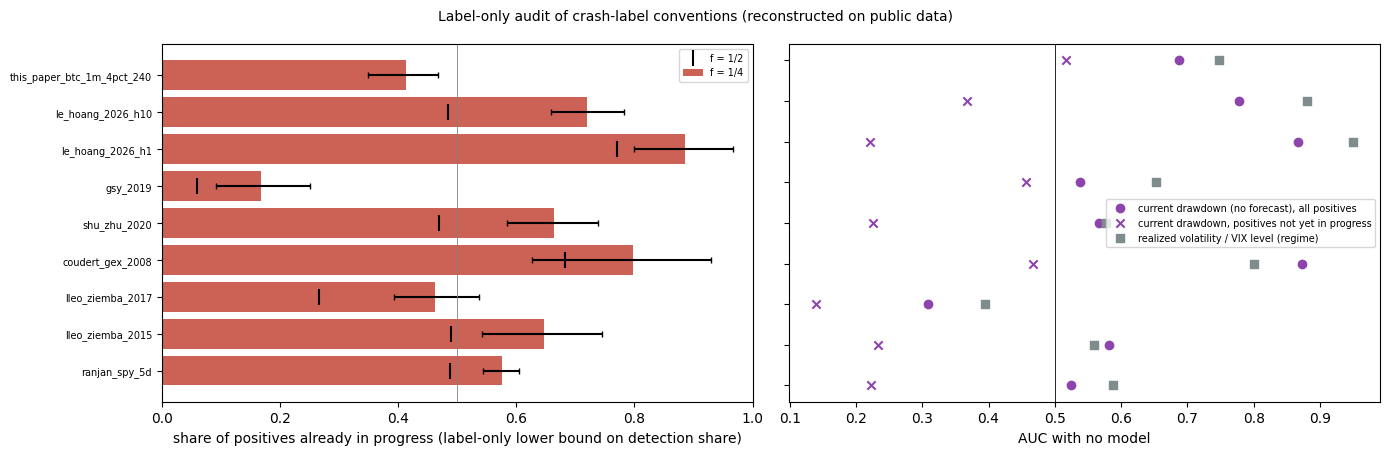

ranjan_spy_5d                n=  8460 pos=24.2% | pi(1/4) 57.6% [54%, 60%] | no-forecast drawdown AUC 0.524 (not-yet 0.222) | volatility/regime AUC 0.588 (not-yet 0.538)
lleo_ziemba_2015             n= 18931 pos=31.5% | pi(1/4) 64.7% [54%, 74%] | no-forecast drawdown AUC 0.581 (not-yet 0.233) | volatility/regime AUC 0.559 (not-yet 0.394)
lleo_ziemba_2017             n= 18679 pos=54.9% | pi(1/4) 46.3% [39%, 54%] | no-forecast drawdown AUC 0.308 (not-yet 0.140) | volatility/regime AUC 0.395 (not-yet 0.309)
coudert_gex_2008             n=   818 pos=15.0% | pi(1/4) 79.7% [63%, 93%] | no-forecast drawdown AUC 0.873 (not-yet 0.468) | volatility/regime AUC 0.801 (not-yet 0.697)
shu_zhu_2020                 n=  4366 pos=18.6% | pi(1/4) 66.5% [58%, 74%] | no-forecast drawdown AUC 0.567 (not-yet 0.226) | volatility/regime AUC 0.577 (not-yet 0.505)
gsy_2019                     n=  3147 pos=34.1% | pi(1/4) 16.8% [9%, 25%] | no-forecast drawdown AUC 0.538 (not-yet 0.457) | volatility/regime AUC 0.6

In [4]:
A = AUD.dropna(subset=['pi_q']).reset_index(drop=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
yy_ = np.arange(len(A))
ax[0].barh(yy_, A.pi_q, color='#c0392b', alpha=0.8, label='f = 1/4')
if 'pi_q_lo' in A:
    ax[0].errorbar(A.pi_q, yy_, xerr=[A.pi_q - A.pi_q_lo, A.pi_q_hi - A.pi_q], fmt='none', ecolor='k', capsize=2)
ax[0].scatter(A.get('pi_h', np.nan), yy_, color='k', marker='|', s=120, label='f = 1/2')
ax[0].set_yticks(yy_); ax[0].set_yticklabels(A.convention, fontsize=7); ax[0].set_xlim(0, 1); ax[0].axvline(0.5, color='grey', lw=0.6)
ax[0].set_xlabel('share of positives already in progress (label-only lower bound on detection share)'); ax[0].legend(fontsize=7)
ax[1].scatter(A.drawdown_auc, yy_, color='#8e44ad', label='current drawdown (no forecast), all positives')
ax[1].scatter(A.drawdown_auc_not_yet, yy_, color='#8e44ad', marker='x', label='current drawdown, positives not yet in progress')
ax[1].scatter(A.vol_auc, yy_, color='#7f8c8d', marker='s', label='realized volatility / VIX level (regime)')
ax[1].axvline(0.5, color='k', lw=0.6); ax[1].set_yticks(yy_); ax[1].set_yticklabels([]); ax[1].set_xlabel('AUC with no model'); ax[1].legend(fontsize=7)
plt.suptitle('Label-only audit of crash-label conventions (reconstructed on public data)', fontsize=10); plt.tight_layout()
plt.savefig(OUT / '2_label_only_audit.png', dpi=140); plt.show()
(OUT / 'AUDIT_SUMMARY.json').write_text(json.dumps(dict(spec_sha256=SPEC_SHA, status='descriptive; label conventions reconstructed approximately; no study result evaluated',
                                                        manifest=MANI, audit=AUD.to_dict('records')), indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o)))
for r in A.itertuples():
    print(f'{r.convention:28s} n={r.n:6d} pos={r.positive_rate:5.1%} | pi(1/4) {r.pi_q:5.1%}'
          + (f' [{r.pi_q_lo:.0%}, {r.pi_q_hi:.0%}]' if np.isfinite(getattr(r, 'pi_q_lo', np.nan)) else '')
          + f' | no-forecast drawdown AUC {r.drawdown_auc:.3f} (not-yet {r.drawdown_auc_not_yet:.3f}) | volatility/regime AUC {r.vol_auc:.3f} (not-yet {r.vol_auc_not_yet:.3f})')

## Interpretation
- π(1/4): the share of positives, under this labeling, at which a decline (or a VIX rise) is already under way. For a model that ranks in-progress positives at least as high as pre-onset positives, at least this share of its skill is detection.
- Current-drawdown AUC: the AUC that a score measuring only how far the price has already fallen (no forecast content) earns on this label; when it lies well above 0.5, the label rewards a score that forecasts nothing. `not_yet` restricts the positives to those not yet in progress.
- Volatility/VIX AUC: the AUC from the regime alone, the minimum benchmark for a model's standard AUC.
- `anchor`: labels anchored at a past peak or a fixed threshold (the paper's 4% crash, Lleo & Ziemba 2017, Coudert & Gex, Le & Hoang) give a decline already under way a mechanical head start. Forward-return labels anchored at the current price (Ranjan, Lleo & Ziemba 2015, Shu & Zhu) do not, so I expect their current-drawdown AUC near 0.5, while π still measures the share of positives that come after the decline began.